# Loop 3.0 study, type 2 cohort: non-inferiority sample size sensitivity

**Question (MC, 2026-11-10).** For the type 2 cohort of the Loop 3.0 study, how do sample size and power move when the assumed Loop 3.0 mean time in range (TIR) rises in 2-point steps and the assumed SD falls in 2-point steps, and what must be assumed to reach at least 80% power with 40 to 50 participants?

**Source.** The Jaeb memo *Loop 3.0 Sample Size* dated 2026-11-02, section "Sample Size using Published TIR References in IOBP2 and 2IQP", Table 5. The type 2 comparator is the 2IQP automated-insulin-delivery arm at week 13: mean TIR 64%, SD 16%, N 214 (memo Table 4). The memo labels that comparator "OP5"; 2IQP (NCT05785832) evaluated Tandem Control-IQ+, not Omnipod 5.

**Method.** The memo's test is a one-sample comparison of the Loop 3.0 mean TIR against the comparator mean minus a 5-point margin: non-inferior if the lower bound of the two-sided 95% confidence interval exceeds 59%. That is a one-sided test at 0.025. Section 1 sets out the test and its exact noncentral-t power. Section 2 reproduces the memo's Table 5 with it, which fixes the method and the significance level the memo used.

**Reference points.** The memo's comparator of 64% and the twiist-T2D single-arm pivotal result of 73% (Levy et al., Diabetes Care 2026) are marked on the figure. Both trials gained 16 points from baseline (2IQP 48% to 64%; twiist-T2D 57% to 73%), and both were run with meal announcements.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import nct as noncentral_t
from scipy.stats import t as t_distribution

# Test definition: Jaeb memo "Loop 3.0 Sample Size" (2026-11-02), section 2, Table 5.
COMPARATOR_MEAN_TIR = 64.0     # 2IQP automated-insulin-delivery arm, week 13, N 214 (memo Table 4)
COMPARATOR_SD_TIR = 16.0       # same row of memo Table 4
NON_INFERIORITY_MARGIN = 5.0   # memo: non-inferior if the lower 95% CI bound of mean TIR exceeds 59%
ALPHA_ONE_SIDED = 0.025        # the memo's two-sided 95% CI lower bound, as a one-sided test
DROPOUT_RATE = 0.10            # memo convention: enrolled = ceil(n / 0.9)

# Reference point for the figure, not an assumption of the analysis.
TWIIST_T2D_MEAN_TIR = 73.0     # twiist-T2D pivotal, week 13, single arm (Levy et al., Diabetes Care 2026)

# Sensitivity grid (MC, 2026-11-10): expected TIR up in 2-point steps, SD down in 2-point steps.
ASSUMED_MEANS = [64, 66, 68, 70, 72, 74]
ASSUMED_SDS = [18, 16, 14, 12, 10]
TARGET_POWERS = [0.80, 0.90]
FIXED_SAMPLE_SIZES = [40, 45, 50]  # the 40 to 50 participant range asked about
FRONTIER_MEAN_RESOLUTION = 0.1     # resolution of the minimum-assumed-mean search

# Memo Table 5, used as the validation target: (cohort, comparator mean, SD) -> (n at 80%, n at 90%).
MEMO_TABLE_5 = {
    ("T1D", 66, 8): (23, 29), ("T1D", 66, 10): (34, 44), ("T1D", 66, 12): (48, 63),
    ("T2D", 64, 14): (64, 85), ("T2D", 64, 16): (86, 110), ("T2D", 64, 18): (104, 139),
}

# House figure style (STYLE.md section 4): brand blues as a light-to-dark ramp over the ordered SDs,
# grey dotted reference lines with right-edge labels, light grey dashed helper lines, 300 dpi.
SD_RAMP = {10: "#c3ccff", 12: "#92a4ff", 14: "#607cff", 16: "#4f59be", 18: "#241144"}
REFERENCE_LINE_COLOR = "#888888"
HELPER_LINE_COLOR = "#CCCCCC"
FONT = {"suptitle": 18, "title": 15, "axis_label": 14, "tick": 12, "legend": 11, "annotation": 13}

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. The test and its power

**What is being tested.** Each of the $n$ participants who complete the primary phase contributes one number, their time in range over the phase, $Y_i$. The analysis treats $Y_1, \dots, Y_n$ as independent draws from a normal distribution with mean $\mu$ and standard deviation $\sigma$. The comparator mean is $\mu_0 = 64$ and the margin is $\delta = 5$, so the threshold the Loop 3.0 mean has to clear is $\theta = \mu_0 - \delta = 59$. The hypotheses are

$$H_0:\ \mu \le \theta \qquad\text{against}\qquad H_1:\ \mu > \theta .$$

Non-inferiority is the alternative. The memo's phrasing, "the 95% confidence interval lower bound of the mean Loop 3.0 TIR exceeds 59%", is this test at one-sided level $\alpha = 0.025$. The lower limit of a two-sided 95% interval is $\bar Y - t_{0.975,\,n-1}\, S/\sqrt{n}$, and it exceeds $\theta$ exactly when

$$T = \frac{\bar Y - \theta}{S/\sqrt{n}} > t_{0.975,\,n-1},$$

where $\bar Y$ is the sample mean, $S$ the sample standard deviation, and $t_{0.975,\,n-1}$ the 97.5th percentile of Student's $t$ with $n-1$ degrees of freedom. The code calls that percentile `critical_value`.

**Where power comes from.** Power is the probability that $T$ clears the critical value when the true mean is some assumed $\mu$ above $\theta$. Write $T$ as a ratio:

$$T = \frac{(\bar Y - \theta)\big/(\sigma/\sqrt{n})}{S/\sigma}.$$

The numerator is normal with variance 1 and mean

$$\lambda = \frac{\mu - \theta}{\sigma/\sqrt{n}} = \frac{(\mu-\theta)\sqrt{n}}{\sigma},$$

the true excess over the threshold measured in standard errors. The denominator is $\sqrt{\chi^2_{n-1}/(n-1)}$ and is independent of the numerator. A unit-variance normal with mean $\lambda$ divided by that root-chi-square is, by definition, a noncentral $t$ with $n-1$ degrees of freedom and noncentrality parameter $\lambda$. So

$$\text{power}(n, \mu, \sigma) = P\!\left(T > t_{0.975,\,n-1}\right) = 1 - F_{t'_{n-1}(\lambda)}\!\left(t_{0.975,\,n-1}\right),$$

with $F_{t'}$ the noncentral-$t$ distribution function. That line is `power_one_sample_non_inferiority` below: `noncentrality` is $\lambda$, `critical_value` is $t_{0.975,\,n-1}$, and `noncentral_t.cdf` is $F_{t'}$.

**Scale of the pieces.** In the memo's equivalence case, $\mu = \mu_0 = 64$, so $\mu - \theta = \delta = 5$: the whole margin is the effect being detected. At $n = 83$ and $\sigma = 16$, $\lambda = 5\sqrt{83}/16 = 2.85$ and the critical value is $t_{0.975,\,82} = 1.99$. The statistic has to land about 1.99 standard errors above zero and is centred 2.85 standard errors above it, which gives power just over 80%. One participant fewer drops it just under. The worked example prints these pieces from the code and asserts them.

**The normal approximation and why it is not used.** Replacing $S$ by $\sigma$ makes $T$ normal, power becomes $\Phi(\lambda - z_{0.975})$, and solving for $n$ gives the textbook formula

$$n \approx \left(\frac{(z_{0.975} + z_{1-\beta})\,\sigma}{\mu - \theta}\right)^2 .$$

For the memo's T2D row at SD 16 this gives 81 where the exact calculation gives 83; for the T1D row at SD 8 it gives 21 where the exact calculation gives 23. The gap is the cost of estimating $\sigma$ from the sample, and it widens as $n$ shrinks. The exact calculation reproduces the memo's table; the approximation does not.

**What the formula says about the levers.** $n$ scales with $\sigma^2$ and inversely with $(\mu - \theta)^2$. Raising the assumed mean from 64 to 66 raises the effect from 5 to 7 points and cuts $n$ by the factor $(5/7)^2 \approx 0.51$. Lowering the SD from 16 to 14 cuts $n$ by $(14/16)^2 \approx 0.77$. That asymmetry is why the mean assumption dominates the grids below.

**Required sample size and the frontier.** Power rises monotonically in $n$ for fixed $\mu > \theta$, so `required_sample_size` steps $n$ upward from 2 and stops at the first value whose exact power reaches the target. Power also rises monotonically in $\mu$ for fixed $n$, so `minimum_assumed_mean` steps $\mu$ upward from $\theta$ on a 0.1-point grid and stops at the first value that reaches the target.

**What the test leaves out.** The comparator mean is treated as a known constant. Its own standard error from 2IQP is $16/\sqrt{214} \approx 1.1$ points, which a two-sample comparison would add in quadrature and which this one-sample test ignores. Normality of time in range is an approximation: the variable is bounded above at 100 and often left-skewed. At $n \ge 40$ the $t$-test for a mean is robust to that shape, and the SD assumption matters far more than it.

In [2]:
def power_one_sample_non_inferiority(n, assumed_mean, assumed_sd, comparator_mean=COMPARATOR_MEAN_TIR):
    """Exact power of the one-sample t-test that the mean TIR exceeds the comparator mean minus the margin.

    Null: mean <= comparator - margin. Alternative: mean > comparator - margin. One-sided at ALPHA_ONE_SIDED.
    Power is the probability, under a true mean of assumed_mean and SD of assumed_sd, that the test rejects.
    """
    degrees_of_freedom = n - 1
    threshold = comparator_mean - NON_INFERIORITY_MARGIN
    noncentrality = (assumed_mean - threshold) * np.sqrt(n) / assumed_sd
    critical_value = t_distribution.ppf(1 - ALPHA_ONE_SIDED, degrees_of_freedom)
    return 1 - noncentral_t.cdf(critical_value, degrees_of_freedom, noncentrality)


def required_sample_size(target_power, assumed_mean, assumed_sd, comparator_mean=COMPARATOR_MEAN_TIR, max_n=5000):
    """Smallest n whose exact power reaches target_power."""
    for n in range(2, max_n + 1):
        if power_one_sample_non_inferiority(n, assumed_mean, assumed_sd, comparator_mean) >= target_power:
            return n
    raise ValueError(f"no n up to {max_n} reaches power {target_power}")


def enrolled_with_dropout(n):
    """Participants to enrol so that n complete, under the memo's dropout convention."""
    return int(np.ceil(n / (1 - DROPOUT_RATE)))


def minimum_assumed_mean(target_power, n, assumed_sd, comparator_mean=COMPARATOR_MEAN_TIR):
    """Smallest assumed mean TIR, on a FRONTIER_MEAN_RESOLUTION grid, giving at least target_power at size n."""
    threshold = comparator_mean - NON_INFERIORITY_MARGIN
    candidates = np.round(np.arange(threshold, 100 + FRONTIER_MEAN_RESOLUTION, FRONTIER_MEAN_RESOLUTION), 1)
    for mean in candidates:
        if power_one_sample_non_inferiority(n, mean, assumed_sd, comparator_mean) >= target_power:
            return float(mean)
    raise ValueError("no assumed mean up to 100 reaches the target power")

### Worked example

In [3]:
# Worked example: the pieces of the power calculation, printed from the code and pinned by asserts.
from scipy.stats import norm


def power_pieces(n, assumed_mean, assumed_sd, comparator_mean=COMPARATOR_MEAN_TIR):
    '''The threshold, noncentrality, critical value, and exact and normal-approximation power for one case.'''
    threshold = comparator_mean - NON_INFERIORITY_MARGIN
    noncentrality = (assumed_mean - threshold) * np.sqrt(n) / assumed_sd
    critical_value = t_distribution.ppf(1 - ALPHA_ONE_SIDED, n - 1)
    return pd.Series({
        "n": n, "assumed_mean": assumed_mean, "assumed_sd": assumed_sd, "threshold": threshold,
        "noncentrality": noncentrality, "critical_value": critical_value,
        "exact_power": power_one_sample_non_inferiority(n, assumed_mean, assumed_sd, comparator_mean),
        "normal_approximation_power": norm.sf(norm.ppf(1 - ALPHA_ONE_SIDED) - noncentrality),
    })


def normal_approximation_n(target_power, assumed_mean, assumed_sd, comparator_mean=COMPARATOR_MEAN_TIR):
    '''The textbook sample size with sigma treated as known.'''
    threshold = comparator_mean - NON_INFERIORITY_MARGIN
    z_sum = norm.ppf(1 - ALPHA_ONE_SIDED) + norm.ppf(target_power)
    return int(np.ceil((z_sum * assumed_sd / (assumed_mean - threshold)) ** 2))


worked = pd.DataFrame([
    power_pieces(83, 64, 16),                   # memo T2D equivalence row at its exact n for 80% power
    power_pieces(82, 64, 16),                   # one participant fewer
    power_pieces(40, 66.3, 16),                 # the 80% frontier at 40 participants and SD 16
    power_pieces(23, 66, 8, comparator_mean=66),  # memo T1D row at SD 8
]).round(4)
display(worked)

approximation = {"T2D SD 16": normal_approximation_n(0.80, 64, 16),
                 "T1D SD 8": normal_approximation_n(0.80, 66, 8, comparator_mean=66)}
print("normal-approximation n for 80% power:", approximation)

assert round(worked.loc[0, "noncentrality"], 2) == 2.85 and round(worked.loc[0, "critical_value"], 2) == 1.99
assert worked.loc[0, "exact_power"] >= 0.80 and worked.loc[1, "exact_power"] < 0.80
assert worked.loc[2, "exact_power"] >= 0.80
assert approximation == {"T2D SD 16": 81, "T1D SD 8": 21}

,n,assumed_mean,assumed_sd,threshold,noncentrality,critical_value,exact_power,normal_approximation_power
0,83.0,64.0,16.0,59.0,2.8470,1.9893,0.8033,0.8125
1,82.0,64.0,16.0,59.0,2.8298,1.9897,0.7985,0.8078
2,40.0,66.3,16.0,59.0,2.8856,2.0227,0.8034,0.8227
3,23.0,66.0,8.0,61.0,2.9974,2.0739,0.8171,0.8502


normal-approximation n for 80% power: {'T2D SD 16': 81, 'T1D SD 8': 21}


## 2. Validation against the memo's Table 5

Each Table 5 row assumes the Loop 3.0 mean equals the comparator mean. Eleven of the twelve cells reproduce exactly. The T2D, SD 16, 80% cell is the one exception: the memo prints 86 where the exact method gives 83. The assert below pins that single discrepancy so that any other drift fails the notebook.

In [4]:
validation_rows = []
for (cohort, comparator_mean, sd), memo_values in MEMO_TABLE_5.items():
    for target_power, memo_n in zip(TARGET_POWERS, memo_values):
        exact_n = required_sample_size(target_power, comparator_mean, sd, comparator_mean=comparator_mean)
        validation_rows.append({
            "cohort": cohort, "comparator_mean_tir": comparator_mean, "assumed_sd": sd,
            "target_power": target_power, "memo_n": memo_n, "exact_n": exact_n, "match": memo_n == exact_n,
        })
validation = pd.DataFrame(validation_rows)
validation.to_csv(OUTPUT_DIR / "table_5_validation.csv", index=False)

mismatches = validation.loc[~validation["match"], ["cohort", "comparator_mean_tir", "assumed_sd", "target_power"]]
mismatch_keys = set(map(tuple, mismatches.itertuples(index=False)))
assert mismatch_keys == {("T2D", 64, 16, 0.80)}, f"unexpected validation drift: {mismatch_keys}"
validation

,cohort,comparator_mean_tir,assumed_sd,target_power,memo_n,exact_n,match
0,T1D,66,8,0.8,23,23,True
1,T1D,66,8,0.9,29,29,True
2,T1D,66,10,0.8,34,34,True
3,T1D,66,10,0.9,44,44,True
4,T1D,66,12,0.8,48,48,True
5,T1D,66,12,0.9,63,63,True
6,T2D,64,14,0.8,64,64,True
7,T2D,64,14,0.9,85,85,True
8,T2D,64,16,0.8,86,83,False
9,T2D,64,16,0.9,110,110,True


## 3. Required sample size by assumed mean and SD

The comparator stays at 64% with the 5-point margin. Rows are the assumed Loop 3.0 SD, columns the assumed Loop 3.0 mean. The 64 column reproduces the memo's equivalence case. Enrolled counts apply the memo's 10% dropout convention.

In [5]:
required_rows = []
for assumed_mean in ASSUMED_MEANS:
    for assumed_sd in ASSUMED_SDS:
        for target_power in TARGET_POWERS:
            n = required_sample_size(target_power, assumed_mean, assumed_sd)
            required_rows.append({
                "assumed_mean_tir": assumed_mean, "assumed_sd": assumed_sd, "target_power": target_power,
                "n_completing": n, "n_enrolled_with_dropout": enrolled_with_dropout(n),
            })
required = pd.DataFrame(required_rows)
required.to_csv(OUTPUT_DIR / "table_t2d_required_n.csv", index=False)

for target_power in TARGET_POWERS:
    print(f"Completing participants for {target_power:.0%} power (rows: assumed SD; columns: assumed mean TIR)")
    display(required[required["target_power"] == target_power]
            .pivot(index="assumed_sd", columns="assumed_mean_tir", values="n_completing")
            .sort_index(ascending=False))

Completing participants for 80% power (rows: assumed SD; columns: assumed mean TIR)


assumed_mean_tir,64,66,68,70,72,74
assumed_sd,,,,,,
18,104,54,34,24,18,14
16,83,43,27,19,14,12
14,64,34,21,15,12,9
12,48,26,16,12,9,8
10,34,19,12,9,7,6


Completing participants for 90% power (rows: assumed SD; columns: assumed mean TIR)


assumed_mean_tir,64,66,68,70,72,74
assumed_sd,,,,,,
18,139,72,44,31,23,18
16,110,57,36,25,18,15
14,85,44,28,20,15,12
12,63,33,21,15,12,9
10,44,24,16,11,9,7


## 4. Power at 40, 45, and 50 completing participants

In [6]:
power_rows = []
for n in FIXED_SAMPLE_SIZES:
    for assumed_mean in ASSUMED_MEANS:
        for assumed_sd in ASSUMED_SDS:
            power_rows.append({
                "n_completing": n, "assumed_mean_tir": assumed_mean, "assumed_sd": assumed_sd,
                "power": power_one_sample_non_inferiority(n, assumed_mean, assumed_sd),
            })
power_at_n = pd.DataFrame(power_rows)
power_at_n.to_csv(OUTPUT_DIR / "table_t2d_power_at_n.csv", index=False)

for n in FIXED_SAMPLE_SIZES:
    print(f"Power with {n} completing participants (rows: assumed SD; columns: assumed mean TIR)")
    display(power_at_n[power_at_n["n_completing"] == n]
            .pivot(index="assumed_sd", columns="assumed_mean_tir", values="power")
            .sort_index(ascending=False)
            .round(3))

Power with 40 completing participants (rows: assumed SD; columns: assumed mean TIR)


assumed_mean_tir,64,66,68,70,72,74
assumed_sd,,,,,,
18,0.403,0.670,0.869,0.965,0.994,0.999
16,0.487,0.770,0.934,0.989,0.999,1.000
14,0.596,0.869,0.977,0.998,1.000,1.000
12,0.729,0.949,0.996,1.000,1.000,1.000
10,0.869,0.991,1.000,1.000,1.000,1.000


Power with 45 completing participants (rows: assumed SD; columns: assumed mean TIR)


assumed_mean_tir,64,66,68,70,72,74
assumed_sd,,,,,,
18,0.445,0.723,0.907,0.980,0.997,1.0
16,0.536,0.819,0.958,0.995,1.000,1.0
14,0.649,0.907,0.988,0.999,1.000,1.0
12,0.780,0.969,0.998,1.000,1.000,1.0
10,0.907,0.996,1.000,1.000,1.000,1.0


Power with 50 completing participants (rows: assumed SD; columns: assumed mean TIR)


assumed_mean_tir,64,66,68,70,72,74
assumed_sd,,,,,,
18,0.486,0.769,0.934,0.989,0.999,1.0
16,0.582,0.858,0.974,0.997,1.000,1.0
14,0.697,0.934,0.994,1.000,1.000,1.0
12,0.823,0.981,0.999,1.000,1.000,1.0
10,0.934,0.998,1.000,1.000,1.000,1.0


## 5. The assumption frontier

For each sample size and SD, the smallest assumed Loop 3.0 mean TIR that gives at least 80% and at least 90% power, searched at 0.1-point resolution. The last column restates the 80% frontier as the margin above the 64% comparator that has to be assumed.

In [7]:
frontier_rows = []
for n in FIXED_SAMPLE_SIZES:
    for assumed_sd in ASSUMED_SDS:
        mean_for_80 = minimum_assumed_mean(0.80, n, assumed_sd)
        mean_for_90 = minimum_assumed_mean(0.90, n, assumed_sd)
        frontier_rows.append({
            "n_completing": n, "assumed_sd": assumed_sd,
            "min_assumed_mean_for_80pct_power": mean_for_80,
            "min_assumed_mean_for_90pct_power": mean_for_90,
            "points_above_comparator_for_80pct": round(mean_for_80 - COMPARATOR_MEAN_TIR, 1),
        })
frontier = pd.DataFrame(frontier_rows)
frontier.to_csv(OUTPUT_DIR / "table_t2d_assumption_frontier.csv", index=False)
frontier

,n_completing,assumed_sd,min_assumed_mean_for_80pct_power,min_assumed_mean_for_90pct_power,points_above_comparator_for_80pct
0,40,18,67.2,68.5,3.2
1,40,16,66.3,67.5,2.3
2,40,14,65.4,66.4,1.4
3,40,12,64.5,65.4,0.5
4,40,10,63.6,64.3,-0.4
5,45,18,66.7,67.9,2.7
6,45,16,65.9,67.0,1.9
7,45,14,65.0,66.0,1.0
8,45,12,64.2,65.0,0.2
9,45,10,63.3,64.0,-0.7


## 6. Figure: power against the assumed mean, one line per SD

Panels are the two ends of the asked-about range. The dotted lines mark 80% and 90% power. The dashed verticals mark the memo's comparator mean and the twiist-T2D mean.

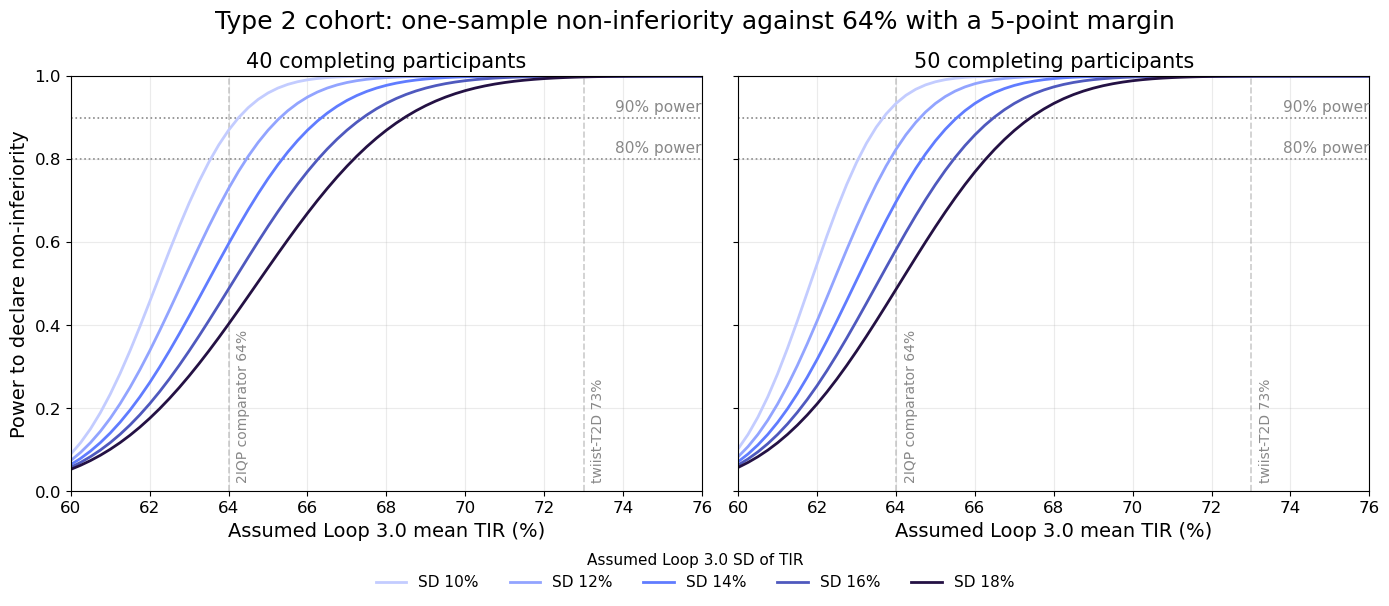

In [8]:
assumed_mean_grid = np.arange(60, 76.01, 0.25)
figure, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for axis, n in zip(axes, [FIXED_SAMPLE_SIZES[0], FIXED_SAMPLE_SIZES[-1]]):
    for assumed_sd in sorted(ASSUMED_SDS):
        power_curve = [power_one_sample_non_inferiority(n, mean, assumed_sd) for mean in assumed_mean_grid]
        axis.plot(assumed_mean_grid, power_curve, color=SD_RAMP[assumed_sd], linewidth=2, label=f"SD {assumed_sd}%")
    for target_power in TARGET_POWERS:
        axis.axhline(target_power, color=REFERENCE_LINE_COLOR, linestyle=":", linewidth=1.2, zorder=0)
        axis.text(assumed_mean_grid[-1], target_power + 0.008, f"{target_power:.0%} power",
                  ha="right", va="bottom", fontsize=FONT["annotation"] - 2, color=REFERENCE_LINE_COLOR)
    for reference_mean, label in [(COMPARATOR_MEAN_TIR, "2IQP comparator"), (TWIIST_T2D_MEAN_TIR, "twiist-T2D")]:
        axis.axvline(reference_mean, color=HELPER_LINE_COLOR, linestyle="--", linewidth=1.2, zorder=0)
        axis.text(reference_mean + 0.2, 0.02, f"{label} {reference_mean:.0f}%", rotation=90,
                  ha="left", va="bottom", fontsize=FONT["annotation"] - 3, color=REFERENCE_LINE_COLOR)
    axis.set_title(f"{n} completing participants", fontsize=FONT["title"])
    axis.set_xlabel("Assumed Loop 3.0 mean TIR (%)", fontsize=FONT["axis_label"])
    axis.set_xlim(assumed_mean_grid[0], assumed_mean_grid[-1])
    axis.set_ylim(0, 1)
    axis.tick_params(labelsize=FONT["tick"])
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Power to declare non-inferiority", fontsize=FONT["axis_label"])
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=len(ASSUMED_SDS), fontsize=FONT["legend"],
              title="Assumed Loop 3.0 SD of TIR", title_fontsize=FONT["legend"], frameon=False,
              bbox_to_anchor=(0.5, -0.01))
figure.suptitle("Type 2 cohort: one-sample non-inferiority against 64% with a 5-point margin",
                fontsize=FONT["suptitle"])
figure.tight_layout(rect=(0, 0.07, 1, 1))
figure.savefig(OUTPUT_DIR / "figure_t2d_power_vs_assumed_mean.png", dpi=300, bbox_inches="tight")
plt.show()